In [2]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


# ============================================================
# Operators
# ============================================================

def op_on_site(op: qt.Qobj, N: int, site: int) -> qt.Qobj:
    ops = [qt.qeye(2)] * N
    ops[site] = op
    return qt.tensor(ops)


def two_site_op(opA: qt.Qobj, opB: qt.Qobj, N: int, i: int, j: int) -> qt.Qobj:
    ops = [qt.qeye(2)] * N
    ops[i] = opA
    ops[j] = opB
    return qt.tensor(ops)


# ============================================================
# Hamiltonian
# ============================================================

def kac_factor(N: int, alpha: float) -> float:
    r = np.arange(1, N, dtype=float)
    return np.sum((N - r) / (r ** alpha)) / (N - 1)


def build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False):

    sx, sz = qt.sigmax(), qt.sigmaz()
    H = 0

    if kac:
        Jx = Jx / kac_factor(N, alpha)

    # field
    for j in range(N):
        H += Bz * op_on_site(sz, N, j)

    # zz NN
    for j in range(N - 1):
        H += Jz * two_site_op(sz, sz, N, j, j + 1)

    # xx long-range
    if alpha >= 100:
        for j in range(N - 1):
            H += Jx * two_site_op(sx, sx, N, j, j + 1)
    else:
        for i in range(N):
            for j in range(i + 1, N):
                r = j - i
                H += (Jx / (r ** alpha)) * two_site_op(sx, sx, N, i, j)

    return H


# ============================================================
# Initial state (x-basis)
# ============================================================

def product_state_x_pm(pm: str) -> qt.Qobj:
    plus = (qt.basis(2,0) + qt.basis(2,1)).unit()
    minus = (qt.basis(2,0) - qt.basis(2,1)).unit()

    kets = [plus if c == "+" else minus for c in pm]
    return qt.tensor(kets).unit()


# ============================================================
# Basis rotation (Z -> X)
# ============================================================

def hadamard():
    return (qt.sigmax() + qt.sigmaz()) / np.sqrt(2)


def x_basis_unitary(N):
    return qt.tensor([hadamard()] * N)


# ============================================================
# Band mask (in Z basis AFTER rotation)
# ============================================================

def band_mask(N, target_band):
    dim = 2**N
    mask = np.zeros(dim, dtype=bool)

    for i in range(dim):
        if bin(i).count("1") == target_band:
            mask[i] = True

    return mask


# ============================================================
# Compute P_stay(t) (C-style)
# ============================================================

def compute_Pstay(H, psi0, target_band, times):

    N = int(np.log2(H.shape[0]))

    # rotate to x-basis
    U = x_basis_unitary(N)
    Hx = U * H * U.dag()
    psi0_x = U * psi0

    # precompute band mask
    mask = band_mask(N, target_band)

    # evolve
    result = qt.sesolve(Hx, psi0_x, times)

    P = np.zeros(len(times))

    for ti, psi_t in enumerate(result.states):
        probs = np.abs(psi_t.full().flatten())**2
        P[ti] = np.sum(probs[mask])

    return P



In [ ]:
import numpy as np

# Parameters
N = 10
Jz = 1.0
Bz = 1.0
alpha = 0
psi0string = "+-" + "+" * (N - 2)
target_band = psi0string.count("-")
psi0 = product_state_x_pm(psi0string)
tmax = 100
times = np.linspace(0, tmax, 5000)

# ============================================================
# COMPUTE AND SAVE LEAKAGE DATA
# ============================================================

Jx_list = np.linspace(1, 20, 10)  # Example range for Jx
avg_leakage = []

for Jx in Jx_list:
    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False)
    P_t = compute_Pstay(H, psi0, target_band, times)

    # Time average (averaging over the second half to avoid initial transients)
    P_stay_avg = np.mean(P_t[len(times) // 2 :])

    # Leakage = 1 - P_stay
    avg_leakage.append(1 - P_stay_avg)

# Save arrays to a single compressed file
np.savez("leakage_data.npz", Jx_list=Jx_list, avg_leakage=avg_leakage)
print("Data successfully saved to 'leakage_data.npz'.")

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20.]


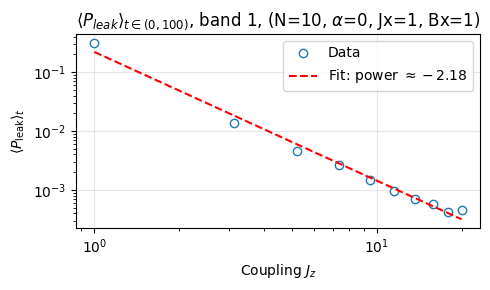

Calculated Power Law Exponent: -2.1847


In [3]:
from scipy.stats import linregress
# Parameters
N = 10
Jz = 1.0
Bz = 1.0
alpha = 0
psi0string = "+-" + "+"*(N-2)
target_band = psi0string.count("-")
psi0 = product_state_x_pm(psi0string)
tmax = 100
times = np.linspace(0, tmax, 5000)
# ============================================================
# COMPUTE + PLOT TIME-AVERAGED LEAKAGE
# ============================================================

Jx_list = np.linspace(1, 20, 10) # Example range for Jx
avg_leakage = []

for Jx in Jx_list:
    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False)
    P_t = compute_Pstay(H, psi0, target_band, times)
    
    # Time average (averaging over the second half to avoid initial transients)
    # Or simply np.mean(P_t) if you want the full average
    P_stay_avg = np.mean(P_t[len(times)//2:]) 
    
    # Leakage = 1 - P_stay
    avg_leakage.append(1 - P_stay_avg)

# Convert to log-space for fitting
log_Jx = np.log10(Jx_list)
log_leak = np.log10(avg_leakage)

# Fit a line (y = mx + c) to the last few points where Jx is largest
slope, intercept = np.polyfit(log_Jx, log_leak, 1)
fit_line = 10**(slope * log_Jx + intercept)

# ============================================================
# PLOT WITH FIT
# ============================================================
plt.figure(figsize=(5, 3))
plt.plot(Jx_list, avg_leakage, 'o', mfc='white', label="Data")
plt.plot(Jx_list, fit_line, '--', color='red', 
         label=fr"Fit: power $\approx {slope:.2f}$")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Coupling $J_z$")
plt.ylabel(r"$\langle P_{\mathrm{leak}} \rangle_t$")
plt.title(fr"$\langle P_{{leak}} \rangle_{{t\in{0,tmax}}}$, band 1, (N={N}, $\alpha$={alpha}, Jx=1, Bx=1)")
plt.grid(True, which="major", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("plt/Pleak_Jx.pdf")
plt.show()

print(f"Calculated Power Law Exponent: {slope:.4f}")

In [ ]:
import numpy as np
import os
import pandas as pd

# Parameters
N_list = np.arange(14, 16, 1)  
Jx_fixed = 100.0
Jz = 1.0
Bz = 1.0
alpha = 0
tmax = 100
times = np.linspace(0, tmax, 5000)

# Ensure the directory exists
output_dir = "ED_Data/SectorConfinement"
os.makedirs(output_dir, exist_ok=True)

# We'll also keep a summary list to save a final scaling file
summary_data = []

for N in N_list:
    print(f"Running simulation for N = {N}...")
    
    # Setup initial state
    psi0string = "+-" + "+"*(N-2)
    target_band = psi0string.count("-")
    psi0 = product_state_x_pm(psi0string)
    
    # Build Hamiltonian and compute Stay Probability
    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx_fixed, alpha, kac=False)
    P_t = compute_Pstay(H, psi0, target_band, times)
    
    # Calculate leakage time series
    leakage_t = 1 - P_t
    
    # --- SAVE FULL TIME SERIES ---
    # Filename: e.g., leakage_N4_Jx2.0.csv
    filename = f"leakage_N{N}_Jx{Jx_fixed:.2f}.csv"
    filepath = os.path.join(output_dir, filename)
    
    df = pd.DataFrame({
        "time": times,
        "leakage": leakage_t
    })
    df.to_csv(filepath, index=False)
    
    # --- CALCULATE TIME AVERAGE ---
    # Averaging the second half to avoid transients
    avg_leak = np.mean(leakage_t[len(times)//2:])
    summary_data.append([N, avg_leak])
    
    print(f"  Done. Avg Leakage: {avg_leak:.6e}. Data saved to {filename}")

# --- SAVE SUMMARY FILE ---
# This makes plotting the scaling law much easier later
summary_df = pd.DataFrame(summary_data, columns=["N", "avg_leakage"])
summary_path = os.path.join(output_dir, f"scaling_Jx{Jx_fixed:.2f}_alpha{alpha}.csv")
summary_df.to_csv(summary_path, index=False)

print("\nAll simulations complete.")
print(f"Summary scaling data saved to: {summary_path}")

Running simulation for N = 4...
  Done. Avg Leakage: 5.011194e-01. Data saved to leakage_N4_Jx100.00.csv
Running simulation for N = 5...
  Done. Avg Leakage: 4.543700e-01. Data saved to leakage_N5_Jx100.00.csv
Running simulation for N = 6...
  Done. Avg Leakage: 3.083992e-02. Data saved to leakage_N6_Jx100.00.csv
Running simulation for N = 7...
  Done. Avg Leakage: 2.004268e-04. Data saved to leakage_N7_Jx100.00.csv
Running simulation for N = 8...
  Done. Avg Leakage: 3.277702e-05. Data saved to leakage_N8_Jx100.00.csv
Running simulation for N = 9...
  Done. Avg Leakage: 1.383802e-04. Data saved to leakage_N9_Jx100.00.csv
Running simulation for N = 10...
  Done. Avg Leakage: 1.619074e-02. Data saved to leakage_N10_Jx100.00.csv
Running simulation for N = 11...
  Done. Avg Leakage: 8.724826e-01. Data saved to leakage_N11_Jx100.00.csv
Running simulation for N = 12...
  Done. Avg Leakage: 9.980799e-01. Data saved to leakage_N12_Jx100.00.csv
Running simulation for N = 13...
  Done. Avg Leak

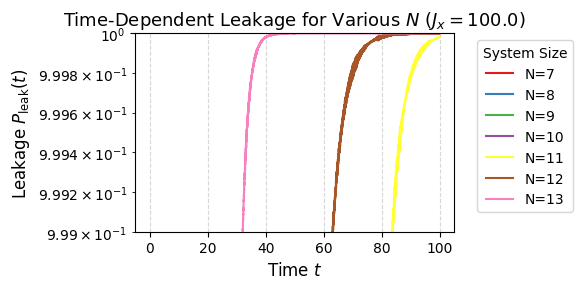

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# Parameters
N_list = np.arange(7, 15, 1)
Jx_fixed = 100.00
data_dir = "ED_Data/SectorConfinement"

plt.figure(figsize=(6, 3))

# Use a colormap to distinguish different N values
colors = plt.cm.Set1(np.linspace(0, 1, len(N_list)))

for i, N in enumerate(N_list):
    filename = f"leakage_N{N}_Jx{Jx_fixed:.2f}.csv"
    filepath = os.path.join(data_dir, filename)
    
    if os.path.exists(filepath):
        df = pd.read_csv(filepath)
        
        # Plotting the leakage over time
        plt.plot(df["time"],df["leakage"], label=f"N={N}", color=colors[i])
    else:
        print(f"Warning: File {filename} not found.")

# --- FORMATTING ---
plt.xlabel("Time $t$", fontsize=12)
plt.ylabel(r"Leakage $P_{\mathrm{leak}}(t)$", fontsize=12)
plt.title(f"Time-Dependent Leakage for Various $N$ ($J_x={Jx_fixed}$)", fontsize=13)

# You can toggle these to 'log' or 'linear' depending on the behavior you see
plt.xscale("linear") 
plt.yscale("log")
plt.ylim(9.99e-1,1)

plt.grid(True, which="major", ls="--", alpha=0.5)
plt.legend(title="System Size", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Save the plot
# plt.savefig("plt/Leakage_Time_Evolution.pdf")
plt.show()

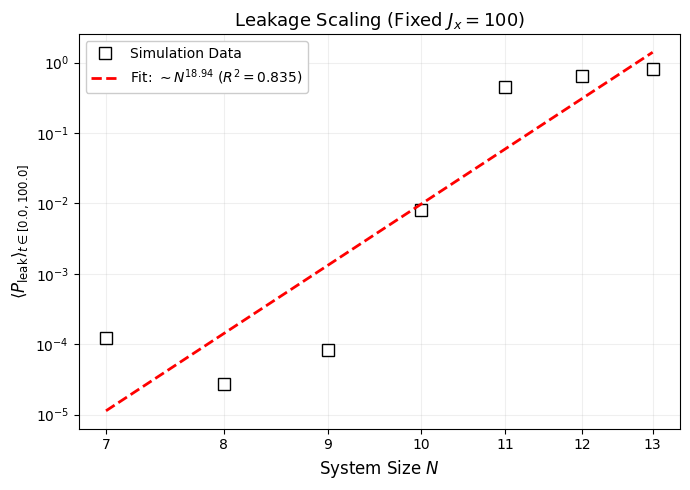

Calculated Power Law Exponent: 18.9416


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress
import os

# --- CONTROL PARAMETERS ---
t_min = 0.0       # Start of averaging window
t_max = 100.0      # End of averaging window
Jx_fixed = 100
alpha = 0
N_list = np.arange(7, 15, 1)
data_dir = "ED_Data/SectorConfinement"

avg_leakage_list = []
valid_N = []

# ============================================================
# DATA PROCESSING
# ============================================================
for N in N_list:
    filename = f"leakage_N{N}_Jx{Jx_fixed:.2f}.csv"
    filepath = os.path.join(data_dir, filename)
    
    if os.path.exists(filepath):
        df = pd.read_csv(filepath)
        
        # Filter for the user-defined time window
        window_mask = (df["time"] >= t_min) & (df["time"] <= t_max)
        window_data = df.loc[window_mask, "leakage"]
        
        if not window_data.empty:
            avg_leak = window_data.mean()
            avg_leakage_list.append(avg_leak)
            valid_N.append(N)
        else:
            print(f"Warning: No data found for N={N} in range [{t_min}, {t_max}]")
    else:
        print(f"Warning: {filename} not found.")

# Convert to arrays for fitting
valid_N = np.array(valid_N)
avg_leakage_list = np.array(avg_leakage_list)

# ============================================================
# SCALING ANALYSIS & PLOT
# ============================================================
log_N = np.log10(valid_N)
log_leak = np.log10(avg_leakage_list)
slope, intercept, r_value, _, _ = linregress(log_N, log_leak)
fit_line = 10**(slope * log_N + intercept)

plt.figure(figsize=(7, 5))

# Plot Data
plt.plot(valid_N, avg_leakage_list, 's', mfc='white', mec='black', 
         markersize=9, label="Simulation Data")

# Plot Power Law Fit
plt.plot(valid_N, fit_line, color='red', ls='--', lw=2,
         label=fr"Fit: $\sim N^{{{slope:.2f}}}$ ($R^2={r_value**2:.3f}$)")

# Formatting
plt.xscale("log")
plt.yscale("log")

# Ensure x-ticks show the actual N values
plt.xticks(valid_N, labels=[str(n) for n in valid_N])
plt.minorticks_off() # Optional: turn off minor ticks for cleaner N labels

plt.xlabel(r"System Size $N$", fontsize=12)
plt.ylabel(fr"$\langle P_{{\mathrm{{leak}}}} \rangle_{{t \in [{t_min}, {t_max}]}}$", fontsize=12)
plt.title(f"Leakage Scaling (Fixed $J_x={Jx_fixed}$)", fontsize=13)

plt.grid(True, which="major", ls="-", alpha=0.2)
plt.legend(frameon=True, facecolor='white', framealpha=1)

plt.tight_layout()
# plt.savefig(f"plt/Scaling_N_tmin{t_min}_tmax{t_max}.pdf")
plt.show()

print(f"Calculated Power Law Exponent: {slope:.4f}")

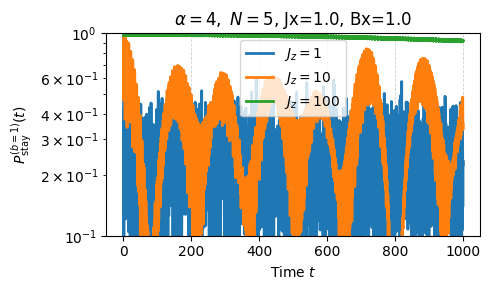

In [3]:

# ============================================================
# PARAMETERS
# ============================================================

N = 5
Jz = 1.0
Bz = 1.0
alpha = 4   # FIXED

Jx_list = [1, 10, 100]

tmax = 1000
times = np.linspace(0, tmax, 5000)

# initial state
psi0string = "+-" + "+"*(N-2)
psi0 = product_state_x_pm(psi0string)

# band = number of '-' spins
target_band = psi0string.count("-")


# ============================================================
# COMPUTE + PLOT
# ============================================================

plt.figure(figsize=(5,3))

for Jx in Jx_list:
    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False)

    P_t = compute_Pstay(H, psi0, target_band, times)

    plt.semilogy(times, P_t, lw=2, label=rf"$J_z={Jx}$")

plt.xlabel("Time $t$")
plt.ylabel(r"$P_{\mathrm{stay}}^{(b=1)}(t)$")
plt.ylim(1e-1,1)
plt.title(rf"$\alpha={alpha},\ N={N}$, Jx={Jz}, Bx={Bz}")

plt.grid(True, which="major", linestyle="--", linewidth=0.6, alpha=0.6)


plt.legend()
plt.tight_layout()
plt.savefig("plt/Pstay_Jx_alpha4.pdf")
plt.show()

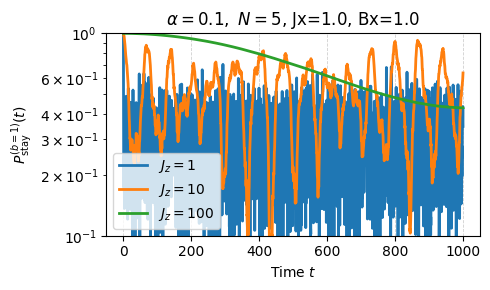

In [4]:

# ============================================================
# PARAMETERS
# ============================================================

N = 5
Jz = 1.0
Bz = 1.0
alpha = 0.1   # FIXED

Jx_list = [1, 10, 100]

tmax = 1000
times = np.linspace(0, tmax, 5000)

# initial state
psi0string = "+-" + "+"*(N-2)
psi0 = product_state_x_pm(psi0string)

# band = number of '-' spins
target_band = psi0string.count("-")


# ============================================================
# COMPUTE + PLOT
# ============================================================

plt.figure(figsize=(5,3))

for Jx in Jx_list:
    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False)

    P_t = compute_Pstay(H, psi0, target_band, times)

    plt.semilogy(times, P_t, lw=2, label=rf"$J_z={Jx}$")

plt.xlabel("Time $t$")
plt.ylabel(r"$P_{\mathrm{stay}}^{(b=1)}(t)$")
plt.ylim(1e-1,1)
plt.title(rf"$\alpha={alpha},\ N={N}$, Jx={Jz}, Bx={Bz}")

plt.grid(True, which="major", linestyle="--", linewidth=0.6, alpha=0.6)


plt.legend()
plt.tight_layout()
plt.savefig("plt/Pstay_Jx_alpha0.1.pdf")
plt.show()

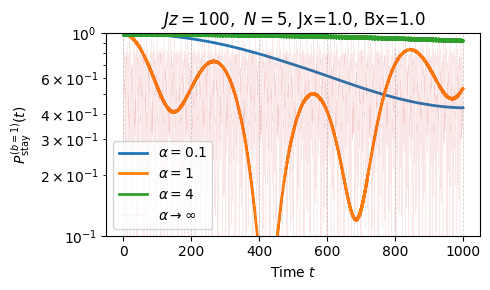

In [6]:

# ============================================================
# PARAMETERS
# ============================================================

N = 5
Jz = 1.0
Bz = 1.0
Jx = 100   # FIXED

Jx_list = [0.1, 1, 4, 1000]

tmax = 1000
times = np.linspace(0, tmax, 5000)

# initial state
psi0string = "+-" + "+"*(N-2)
psi0 = product_state_x_pm(psi0string)

# band = number of '-' spins
target_band = psi0string.count("-")


# ============================================================
# COMPUTE + PLOT
# ============================================================

plt.figure(figsize=(5,3))

for alpha in Jx_list:
    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False)

    P_t = compute_Pstay(H, psi0, target_band, times)

    if alpha >= 1000:
        plt.semilogy(times, P_t, lw=0.1, ls=":", label=rf"$\alpha\to\infty$")
    else:
        plt.semilogy(times, P_t, lw=2, label=rf"$\alpha={alpha}$")

plt.xlabel("Time $t$")
plt.ylabel(r"$P_{\mathrm{stay}}^{(b=1)}(t)$")
plt.ylim(1e-1,1)
plt.title(rf"$Jz={Jx},\ N={N}$, Jx={Jz}, Bx={Bz}")

plt.grid(True, which="major", linestyle="--", linewidth=0.6, alpha=0.6)


plt.legend()
plt.tight_layout()
plt.savefig("plt/Pstay_alpha_Jx100.pdf")
plt.show()